# 04 — Analyse du re-ranker Cross-Encodeur (BGE-reranker-base)

Évaluation de BGE-reranker-base en mode **zero-shot** et **fine-tuné** (5 000 triplets, 1 époque) sur MS MARCO dev.

Pipeline : BM25 top-20 → Cross-encodeur → top-10 final.

## 1. Setup & chargement des métriques

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

RESULTS = Path('../results')
OUT_DIR = RESULTS / 'analysis' / '04_cross_encoder'
OUT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {
    'rouge':      '#C8102E',
    'or':         '#F0A500',
    'bleu_nuit':  '#1A2D5A',
    'gris_fonce': '#4A4A4A',
    'gris_clair': '#D3D3D3',
}

def load(path):
    return json.loads(Path(path).read_text())

bm25   = load(RESULTS / 'baselines/bm25_msmarco_dev/metrics.json')
ce_zs  = load(RESULTS / 'cross_encoder/evaluation/bge_reranker_zs_msmarco_dev/metrics.json')
ce_ft  = load(RESULTS / 'cross_encoder/evaluation/bge_reranker_ft_msmarco_dev/metrics.json')
ce_zs_cfg = load(RESULTS / 'cross_encoder/evaluation/bge_reranker_zs_msmarco_dev/config.json')

print('BM25  MRR@10 =', bm25['MRR@10'])
print('CE ZS MRR@10 =', ce_zs['MRR@10'])
print('CE FT MRR@10 =', ce_ft['MRR@10'])
print(f"Latence CE ZS : {ce_zs_cfg.get('latency_ms_per_query', 11.25):.1f} ms/requête")

BM25  MRR@10 = 0.1697
CE ZS MRR@10 = 0.2965222063037249
CE FT MRR@10 = 0.280554930186019
Latence CE ZS : 11.2 ms/requête


## 2. Figure 1 — Comparaison BM25 / CE zero-shot / CE fine-tuné

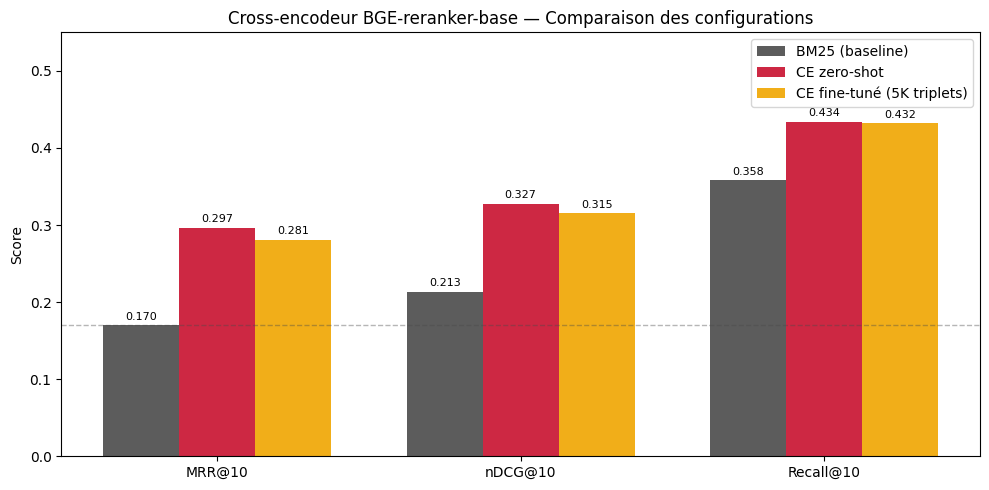

Figure sauvegardée : ../results/analysis/04_cross_encoder/ce_metrics_comparison.png


In [2]:
systems = ['BM25\n(baseline)', 'CE\nzero-shot', 'CE\nfine-tuné\n(5K triplets)']
metrics_labels = ['MRR@10', 'nDCG@10', 'Recall@10']
data = [
    [bm25['MRR@10'],  bm25['nDCG@10'],  bm25['Recall@10']],
    [ce_zs['MRR@10'], ce_zs['nDCG@10'], ce_zs['Recall@10']],
    [ce_ft['MRR@10'], ce_ft['nDCG@10'], ce_ft['Recall@10']],
]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(metrics_labels))
width = 0.25
bar_colors = [COLORS['gris_fonce'], COLORS['rouge'], COLORS['or']]

for i, (sys_data, color, label) in enumerate(zip(data, bar_colors, systems)):
    bars = ax.bar(x + i * width, sys_data, width, label=label.replace('\n', ' '), color=color, alpha=0.9)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x + width)
ax.set_xticklabels(metrics_labels)
ax.set_ylim(0, 0.55)
ax.set_ylabel('Score')
ax.set_title('Cross-encodeur BGE-reranker-base — Comparaison des configurations')
ax.legend()
ax.axhline(y=bm25['MRR@10'], color=COLORS['gris_fonce'], linestyle='--', alpha=0.4, linewidth=1)
plt.tight_layout()
plt.savefig(OUT_DIR / 'ce_metrics_comparison.png', dpi=150)
plt.show()
print(f'Figure sauvegardée : {OUT_DIR / "ce_metrics_comparison.png"}')

## 3. Figure 2 — Gain vs BM25 (delta)

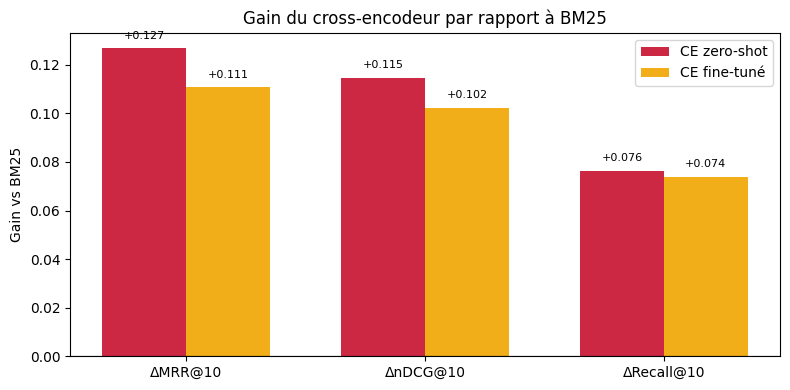

Figure sauvegardée : ../results/analysis/04_cross_encoder/ce_gain_vs_bm25.png


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
deltas = {
    'CE zero-shot': {
        'ΔMRR@10':   ce_zs['MRR@10']  - bm25['MRR@10'],
        'ΔnDCG@10':  ce_zs['nDCG@10'] - bm25['nDCG@10'],
        'ΔRecall@10': ce_zs['Recall@10'] - bm25['Recall@10'],
    },
    'CE fine-tuné': {
        'ΔMRR@10':   ce_ft['MRR@10']  - bm25['MRR@10'],
        'ΔnDCG@10':  ce_ft['nDCG@10'] - bm25['nDCG@10'],
        'ΔRecall@10': ce_ft['Recall@10'] - bm25['Recall@10'],
    },
}

x = np.arange(3)
width = 0.35
for i, (label, d) in enumerate(deltas.items()):
    vals = list(d.values())
    color = COLORS['rouge'] if i == 0 else COLORS['or']
    bars = ax.bar(x + i * width, vals, width, label=label, color=color, alpha=0.9)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + (0.003 if bar.get_height() >= 0 else -0.015),
                f'{bar.get_height():+.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x + width / 2)
ax.set_xticklabels(list(deltas['CE zero-shot'].keys()))
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Gain vs BM25')
ax.set_title('Gain du cross-encodeur par rapport à BM25')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'ce_gain_vs_bm25.png', dpi=150)
plt.show()
print(f'Figure sauvegardée : {OUT_DIR / "ce_gain_vs_bm25.png"}')